In [122]:
import numpy as np
import torch
import algorithms.kernelDL_multistep as kdl
from algorithms.dmd import rffEDMD
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import utils.kernels as kernels
import utils.helpers as helpers
import utils.plotting_params

# koopmanAE
from koopmanAE.model import koopmanAE
from koopmanAE.train import train
from koopmanAE.tools import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


###  Data

In [172]:
vorticity_data = sio.loadmat('data/Karman/V.mat')['V']
mean_flow = vorticity_data.mean(axis=2, keepdims=True)
median_flow = np.median(vorticity_data, axis=2, keepdims=True)

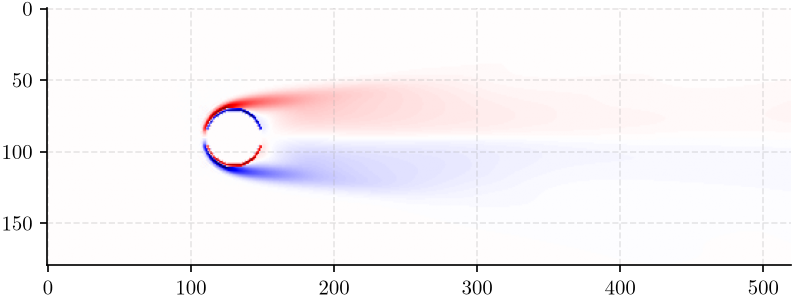

In [173]:
plt.imshow(mean_flow, cmap='seismic');

In [ ]:
H, W, T = vorticity_data.shape  # H: height, W: width, T: time steps
# remove mean flow and vectorize the data
vorticity_data_vec = (vorticity_data - mean_flow).reshape(-1, T)  # shape (T, H*W)

# dimensionality reduction
U, S, Vt = np.linalg.svd(vorticity_data_vec, full_matrices=False)

In [190]:
# retain 95% of the total energy
cum_energy = np.cumsum(S**2) / np.sum(S**2)
r = np.searchsorted(cum_energy, 0.95) + 1
print(f"Retained {r} POD modes out of {len(S)} ")

X_all = S[:r, np.newaxis] * Vt[:r, :]

# split into train/test
p_train = 0.8
X_train, X_test = X_all[:,:int(p_train * T)], X_all[:,int(p_train * T):]

Retained 19 POD modes out of 500 


In [ ]:
# # Dimensionality reduction
# X_train_r = S[:r, np.newaxis] * Vt[:r, :]
# X_test_r = U[:,:r].T @ (X_test - X_train.mean(axis=1, keepdims=True))
# X_all_r = U[:,:r].T @ (X_all - X_train.mean(axis=1, keepdims=True))

# # reconstructed test data
# X_test_recon = U[:,:r] @ X_test_r + X_train.mean(axis=1, keepdims=True)

In [191]:
# scale
A, B = X_train.min(axis=1, keepdims=True), np.ptp(X_train, axis=1, keepdims=True)
X_train_scaled = (X_train - A) / B
X_test_scaled = (X_test - A) / B
X_all_scaled = (X_all - A) / B

**visualize retained POD modes**

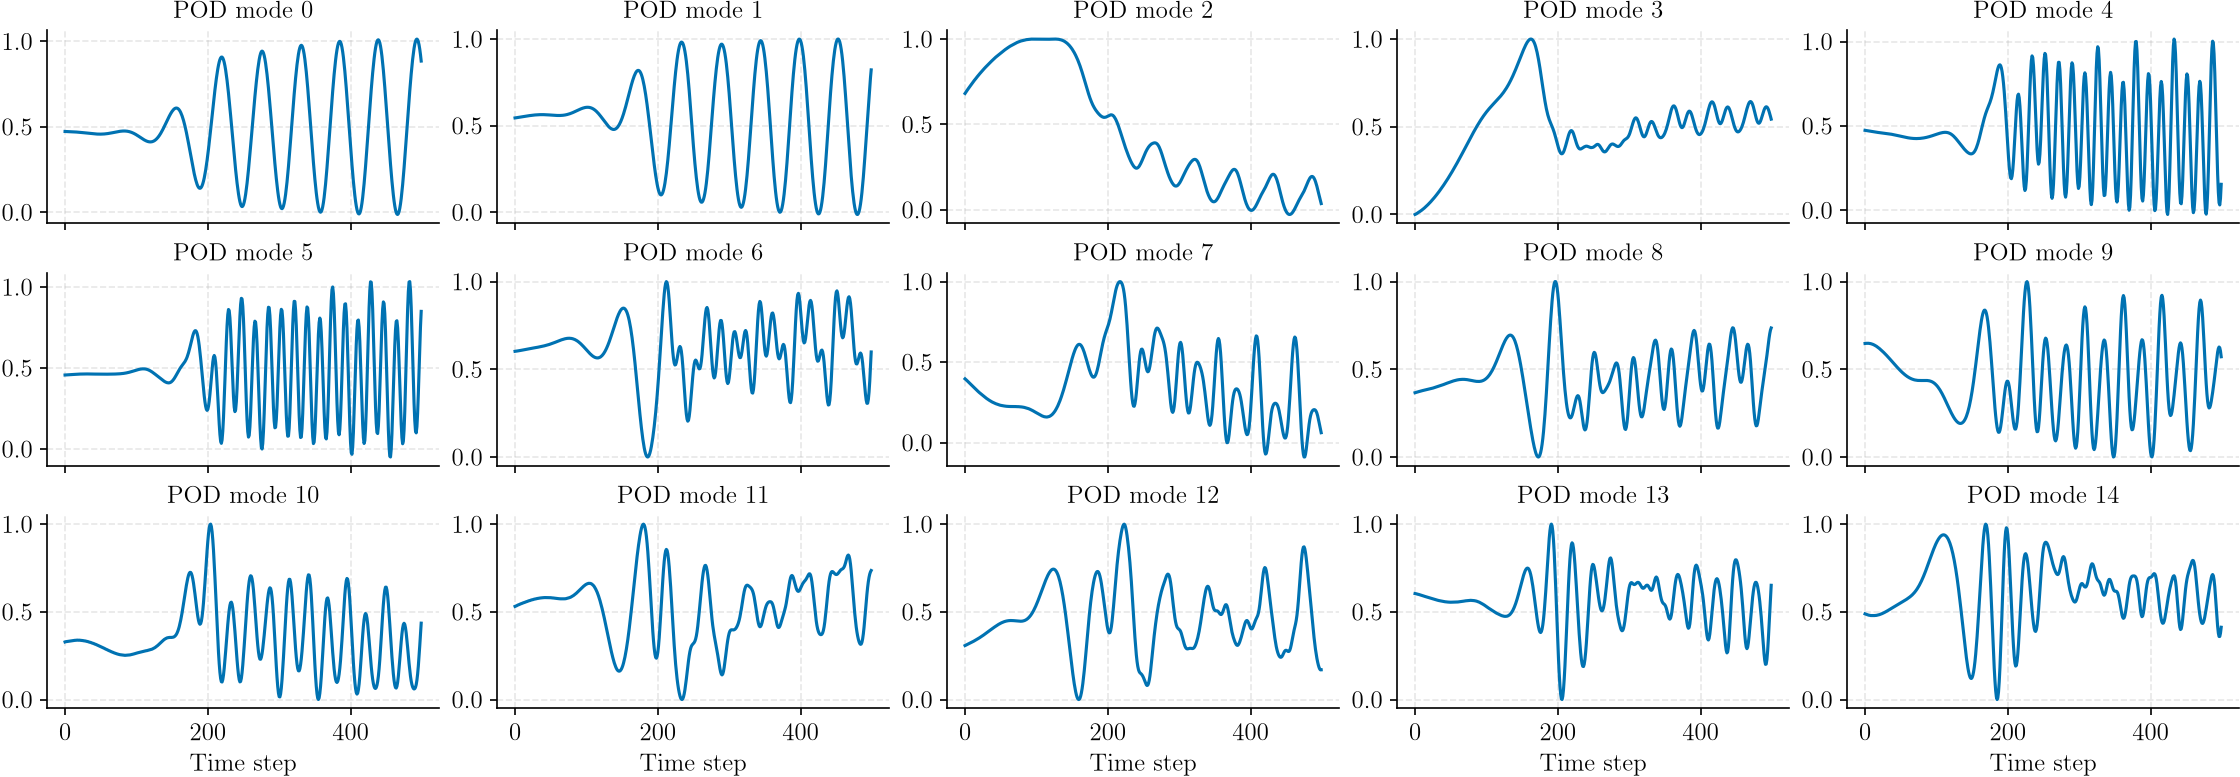

In [328]:
ncols = 5
nrows = 3
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*3, nrows*1.75), sharex=True, constrained_layout=True)
ax = ax.flatten()
for i in range(ncols * nrows):
    ax[i].plot(X_all_scaled[i, :])
    if i >= (nrows - 1) * ncols:
        ax[i].set_xlabel('Time step', fontsize=12)
    ax[i].set_title(f'POD mode {i}', fontsize=12)
    ax[i].tick_params(axis='both', labelsize=12)

plt.show()

### cKAE

In [193]:
steps, steps_back, backward, epochs = 8, 8, 1, 600   # koopmanAE
dim = X_train_scaled.shape[0]
embed_dim = 6
seed = 0
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.manual_seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
set_seed(seed)
device = get_device()

batchsize=64; init_scale=0.99; alpha_=3
lr=1e-2; wd=1e-6; lamb=1; lr_decay=0.2; lr_update=[30, 200, 400, 500];
nu=1e-1; eta=1e-2; gradclip=0.05; 


#****************************************************************
#     prepare dataset for koopmanAE
#****************************************************************
X_train_kae = add_channels(X_train_scaled.T)

# create dataloader
X_train_kae = torch.from_numpy(X_train_kae).float().contiguous()
trainDat = []
start = 0
for i in np.arange(steps,-1, -1):
    if i == 0:
        trainDat.append(X_train_kae[start:].float())
    else:
        trainDat.append(X_train_kae[start:-i].float())
    start += 1

train_data = torch.utils.data.TensorDataset(*trainDat)
del(trainDat)

train_loader = torch.utils.data.DataLoader(dataset = train_data, batch_size = batchsize, shuffle = True)

#*************************************************************
#             Model
#*************************************************************
model = koopmanAE(dim, 1, embed_dim, steps, steps_back, alpha_, init_scale)
model = model.to(device)

print('**** Setup ****')
print('Total params: %.2fM' % (sum(p.numel() for p in model.parameters())/1000000.0))
print('Total params: %.2fk' % (sum(p.numel() for p in model.parameters())/1000.0))
print('************')
print(model)

#==============================================================================
# Training
#==============================================================================
model, optimizer, epoch_hist = train(model, train_loader, lr=lr, weight_decay=wd, lamb=lamb, num_epochs = epochs,
                    learning_rate_change=lr_decay, epoch_update=lr_update,nu = nu, eta = eta, backward=backward,
                    steps=steps, steps_back=steps_back, gradclip=gradclip)

Connected to a GPU
**** Setup ****
Total params: 0.01M
Total params: 7.30k
************
koopmanAE(
  (encoder): encoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=19, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=6, bias=True)
  )
  (dynamics): dynamics(
    (dynamics): Linear(in_features=6, out_features=6, bias=False)
  )
  (backdynamics): dynamics_back(
    (dynamics): Linear(in_features=6, out_features=6, bias=False)
  )
  (decoder): decoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=6, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=19, bias=True)
  )
)
Connected to a GPU
********** Epoche 1 **********
loss identity:  0.44162991642951965
loss backward:  0.6406925320625305
loss consistent:  5.022308349609375
loss forward:  0.637937605381012
loss sum:  1.1938599348068237
********** Epoch

### KAE

In [194]:
backward = 0
seed = 0
set_seed(seed)
embed_dim_kae = 6
alpha_kae = 3

#*************************************************************
#             Model
#*************************************************************
model_kae = koopmanAE(dim, 1, embed_dim_kae, steps, steps_back, alpha_kae, init_scale)
model_kae = model_kae.to(device)

print('**** Setup ****')
print('Total params: %.2fM' % (sum(p.numel() for p in model_kae.parameters())/1000000.0))
print('Total params: %.2fk' % (sum(p.numel() for p in model_kae.parameters())/1000.0))
print('************')
print(model_kae)

#==============================================================================
# Training
#==============================================================================
model_kae, optimizer, epoch_hist = train(model_kae, train_loader, lr=lr, weight_decay=wd, lamb=lamb, num_epochs = epochs,
                    learning_rate_change=lr_decay, epoch_update=lr_update,nu = nu, eta = eta, backward=backward,
                    steps=steps, steps_back=steps_back, gradclip=gradclip)

**** Setup ****
Total params: 0.01M
Total params: 7.30k
************
koopmanAE(
  (encoder): encoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=19, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=6, bias=True)
  )
  (dynamics): dynamics(
    (dynamics): Linear(in_features=6, out_features=6, bias=False)
  )
  (backdynamics): dynamics_back(
    (dynamics): Linear(in_features=6, out_features=6, bias=False)
  )
  (decoder): decoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=6, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=19, bias=True)
  )
)
Connected to a GPU
********** Epoche 1 **********
loss identity:  0.4639126658439636
loss forward:  0.6757951378822327
loss sum:  1.1397078037261963
********** Epoche 21 **********
loss identity:  0.17778223752975464
loss forward:  0.28499963879585266
los

### EDMD-kDL

In [195]:
X, Y = X_train_scaled[:, :-1], X_train_scaled[:, 1:] 

# generate collocation points
dim = X.shape[0]
mc, seed = 8, 42
l_bounds = [X.min() -1.]*dim 
u_bounds = [X.max() + 1.]*dim 
Z = helpers.generate_collocation_points(dim, l_bounds, u_bounds, m=mc, seed=seed).T

In [ ]:
# fixed_feature_fn = lambda x: x
# sigma, p, gamma = 5., dim*2, 1e-5
# kernel = kernels.gaussianKernel(sigma=sigma) 
# edmd_kdl = kdl.EDMDkDL(X=X, Y=Y, Z=Z, kernel=kernel, p=p, gamma=gamma, decoder=False, fixed_feature_fn=fixed_feature_fn)  
# edmd_kdl.optimize(n_iters=800, steps=8, beta1=1, beta2=1., beta3=1e-5, verbose_after=10, lr=1, history_size=60)  

In [319]:
fixed_feature_fn = lambda x: x
sigma, p, gamma = 10., 25, 1e-5
kernel = kernels.gaussianKernel(sigma=sigma) 
edmd_kdl = kdl.EDMDkDL(X=X, Y=Y, Z=Z, kernel=kernel, p=p, gamma=gamma, decoder=True, fixed_feature_fn=fixed_feature_fn)  

In [320]:
edmd_kdl.optimize(n_iters=1000, steps=8, beta1=1, beta2=1., beta3=1e-5, verbose_after=10, lr=1, history_size=60)  

step   0 | loss 1.9e+11
step  10 | loss 1.8e+01
step  20 | loss 6.3e-01
step  30 | loss 4.4e-01
step  40 | loss 3.1e-01
step  50 | loss 2.3e-01
step  60 | loss 1.6e-01
step  70 | loss 1.0e-01
step  80 | loss 6.7e-02
step  90 | loss 4.8e-02
step 100 | loss 3.2e-02
step 110 | loss 2.3e-02
step 120 | loss 1.6e-02
step 130 | loss 9.8e-03
step 140 | loss 6.8e-03
step 150 | loss 5.5e-03
step 160 | loss 4.7e-03
step 170 | loss 4.3e-03
step 180 | loss 3.9e-03
step 190 | loss 3.6e-03
step 200 | loss 3.4e-03
step 210 | loss 3.2e-03
step 220 | loss 2.9e-03
step 230 | loss 2.6e-03
step 240 | loss 2.3e-03
step 250 | loss 2.1e-03
step 260 | loss 2.0e-03
step 270 | loss 1.9e-03
step 280 | loss 1.9e-03
step 290 | loss 1.8e-03
step 300 | loss 1.7e-03
step 310 | loss 1.7e-03
step 320 | loss 1.6e-03
step 330 | loss 1.6e-03
step 340 | loss 1.5e-03
step 350 | loss 1.5e-03
step 360 | loss 1.4e-03
step 370 | loss 1.3e-03
step 380 | loss 1.3e-03
step 390 | loss 1.2e-03
step 400 | loss 1.2e-03
step 410 | loss 

### EDMD-RFF

In [217]:
edmd_rff = rffEDMD(X, Y, sigma=1., decoder=True, rcond=None)
edmd_rff.train(n_features=100)

**eigenvalues**

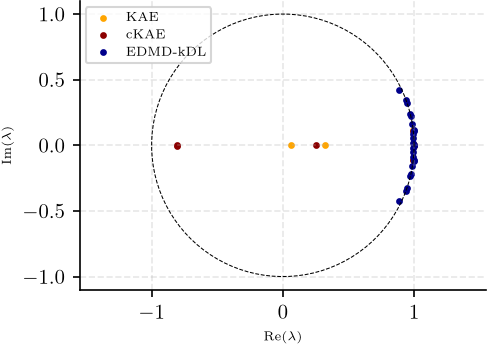

In [321]:
# cKAE
K = model.dynamics.dynamics.weight.data.detach().cpu().numpy()
K_kae = model_kae.dynamics.dynamics.weight.data.detach().cpu().numpy()
eigvals_ckae = np.linalg.eigvals(K)
eigvals_kae = np.linalg.eigvals(K_kae)
eigvals_edmdkdl = edmd_kdl.eigvals
eigvals_edmdrff = np.linalg.eigvals(edmd_rff.K)

fig, ax = plt.subplots(figsize=(3.5, 2.5))
#ax.scatter(eigvals_edmdrff.real, eigvals_edmdrff.imag, color='darkviolet', s=5, label='EDMD-RFF')
ax.scatter(eigvals_kae.real, eigvals_kae.imag, color='orange', s=5, label='KAE')
ax.scatter(eigvals_ckae.real, eigvals_ckae.imag, color='darkred', s=5, label='cKAE')
ax.scatter(eigvals_edmdkdl.real, eigvals_edmdkdl.imag, color='darkblue', s=5, label='EDMD-kDL')
# plot unit circle
theta = np.linspace(0, 2*np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), 'k--', lw=0.5)
ax.set_xlabel(r'Re($\lambda$)', fontsize=6)
ax.set_ylabel(r'Im($\lambda$)', fontsize=6)
ax.axis('equal')
ax.legend(loc='upper left', fontsize=6)
plt.show()

In [276]:
EigVals = [eigvals_edmdrff, eigvals_kae, eigvals_ckae, eigvals_edmdkdl]
labels = ['EDMD-RFF', 'KAE', 'cKAE', 'EDMD-kDL']
colors_list = ['magenta', 'orange', 'darkred', 'darkblue']

fig, axes = plt.subplots(1, len(EigVals), figsize=(5.5, 1.6), constrained_layout=True)

theta = np.linspace(0, 2*np.pi, 200)
unit_circle = np.column_stack([np.cos(theta), np.sin(theta)])

# consistent limits across all panels, based on global max |eigval|
max_extent = max(np.max(np.abs(ev)) for ev in EigVals)
lim = max(1.1, max_extent * 1.1)  # pad beyond unit circle / data, whichever is larger

for i, (ax, eigvals) in enumerate(zip(axes, EigVals)):
    ax.plot(unit_circle[:, 0], unit_circle[:, 1], color='gray', ls='--', lw=0.6, zorder=1)
    ax.vlines(0, -1, 1, color='gray', ls='--', lw=0.2)
    ax.hlines(0, -1, 1, color='gray', ls='--', lw=0.2)
    ax.scatter(eigvals.real, eigvals.imag, color=colors_list[i], s=5, linewidths=0,
               zorder=2, clip_on=False)

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_title(labels[i], fontsize=12, pad=3)
    ax.set_xlabel(r'Re($\lambda$)', fontsize=12)
    ax.tick_params(labelsize=12, length=2)

    if i == 0:
        ax.set_ylabel(r'Im($\lambda$)', fontsize=12)
    else:
        ax.set_yticklabels([])  

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.grid(False)

fig.savefig('figures/karman_vortex_eigvals.pdf', bbox_inches='tight')
plt.close(fig)

In [277]:
EigX = edmd_kdl.eigen_fn(X_all_scaled)

**eigenfunctions**

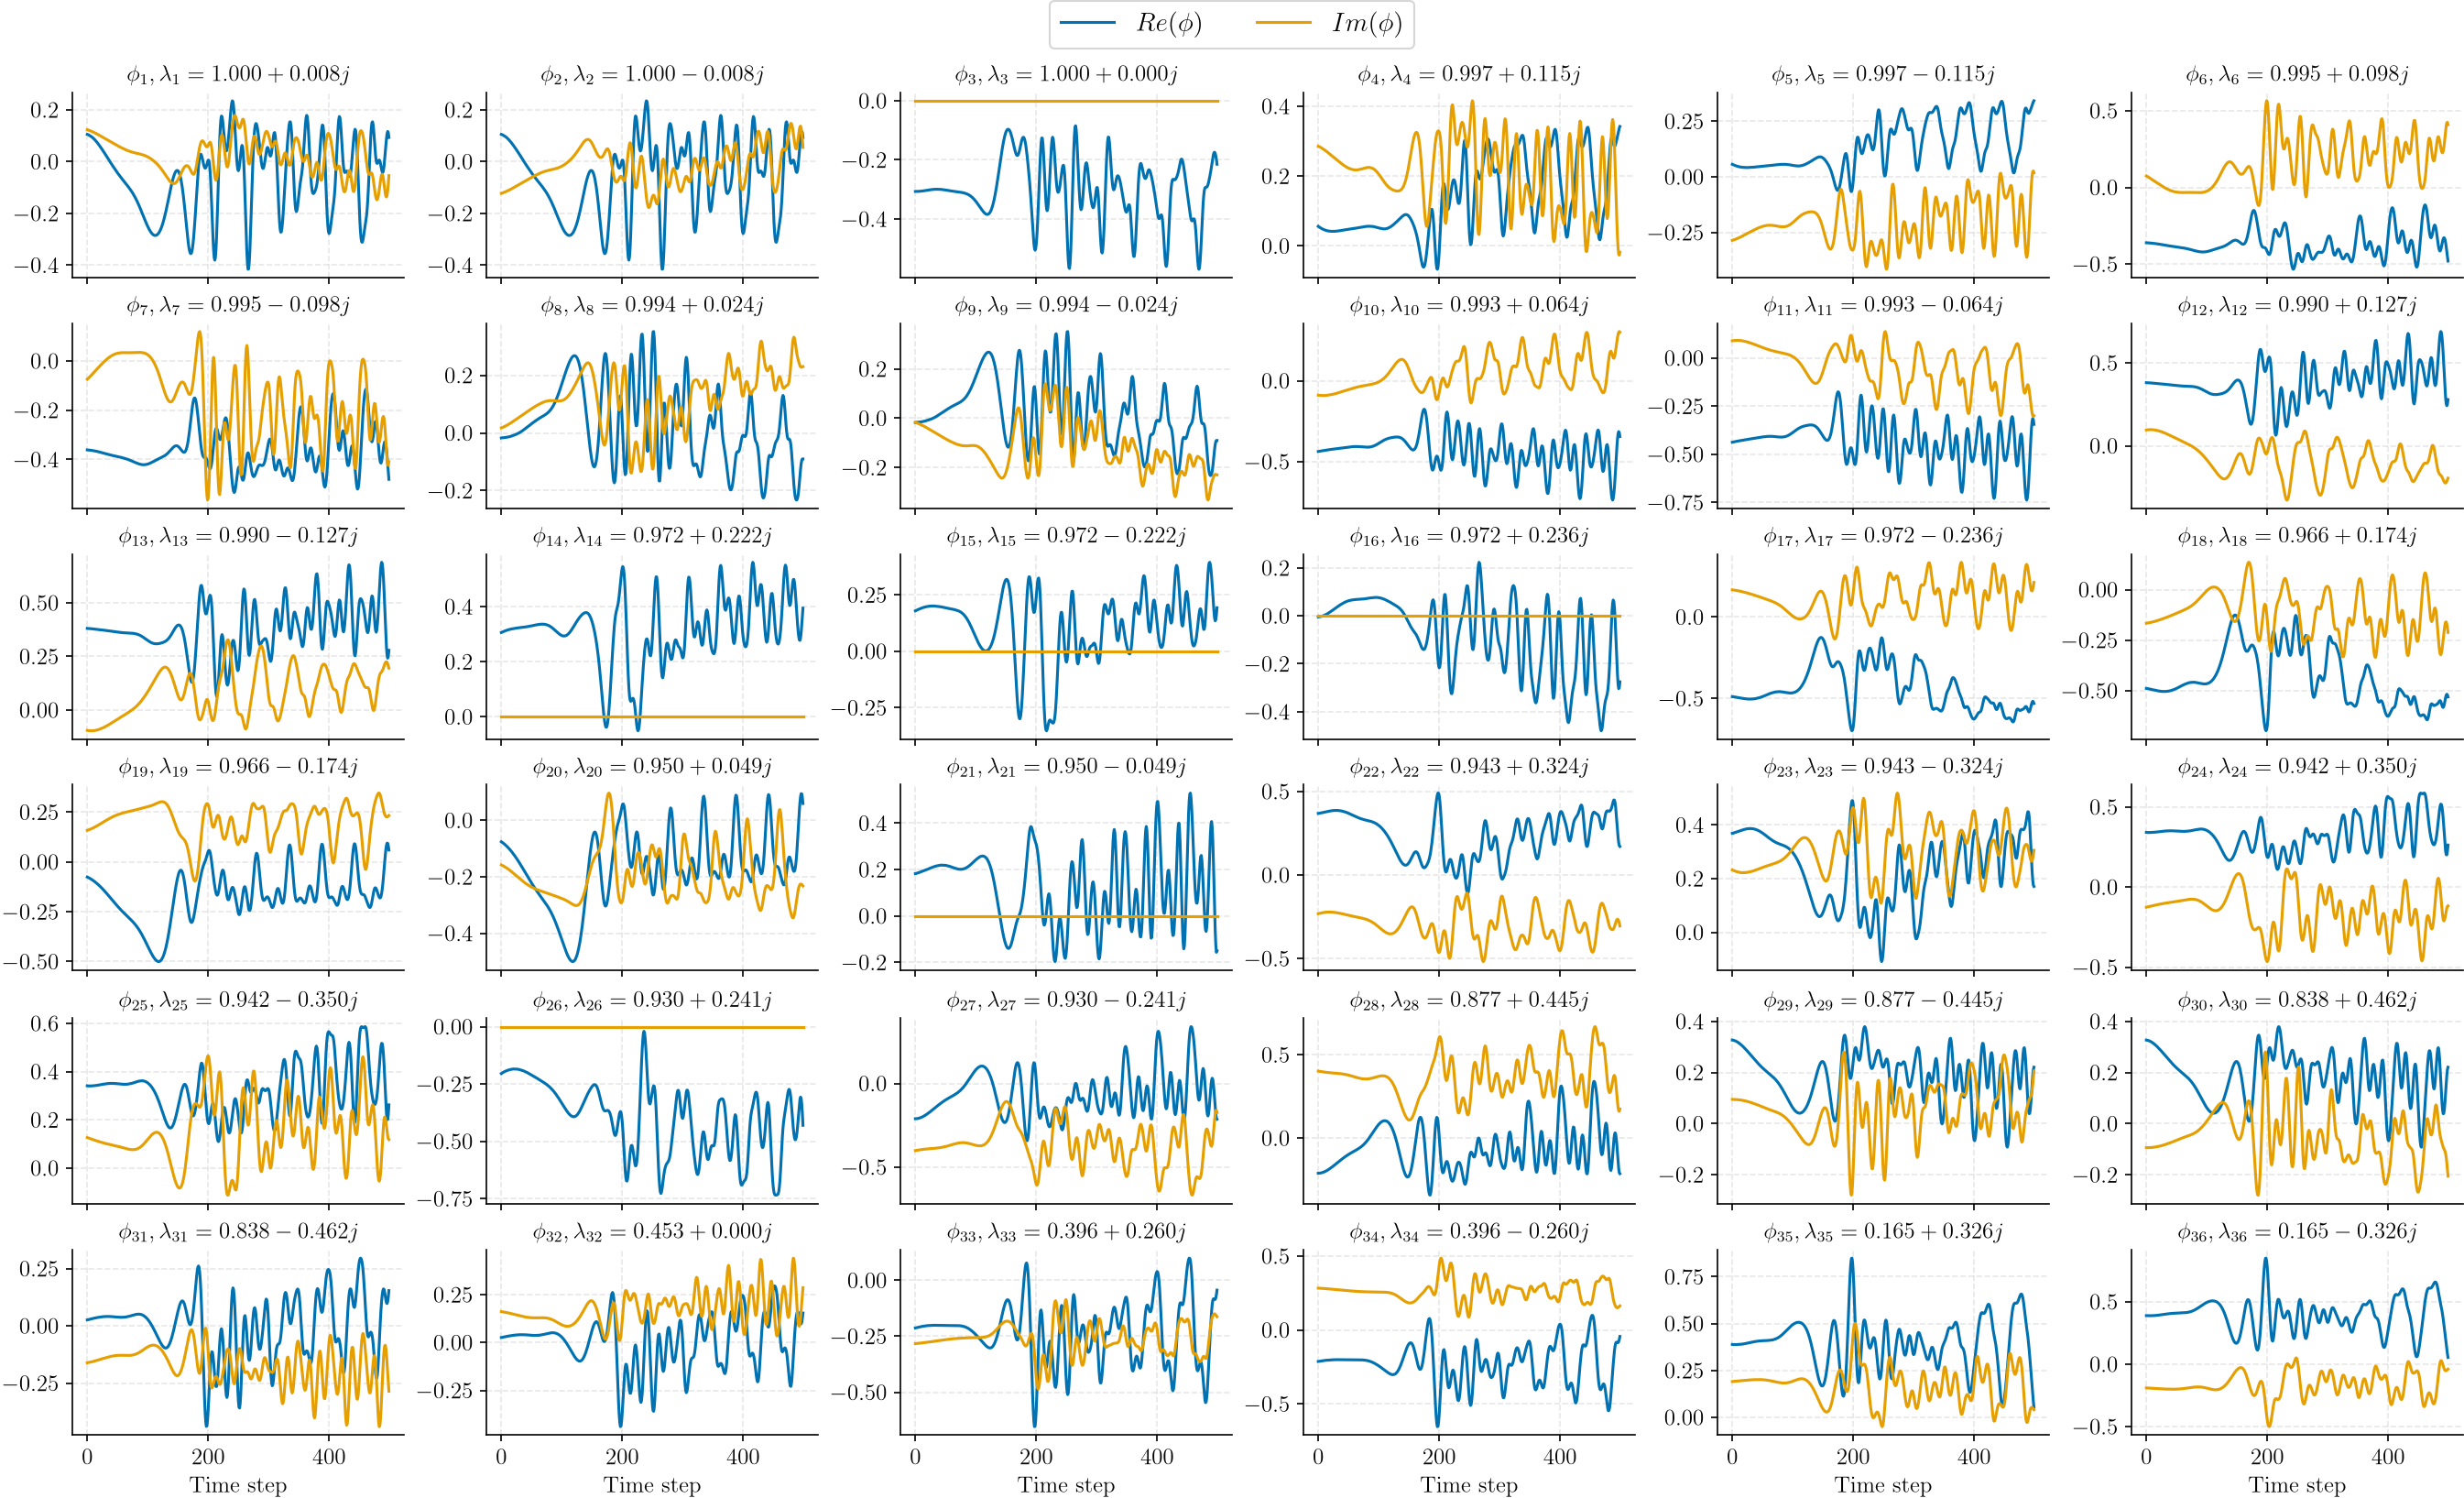

In [278]:
ncols = 6
nrows = 6
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*3., nrows*1.75), sharex=True, constrained_layout=True)
ax = ax.flatten()
for i in range(min(ncols * nrows, EigX.shape[0])):
    ax[i].plot(EigX[i, :].real, label=r'$Re(\phi)$')
    ax[i].plot(EigX[i, :].imag, label=r'$Im(\phi)$')
    if i >= (nrows - 1) * ncols:
        ax[i].set_xlabel('Time step', fontsize=12)
    ax[i].set_title(rf'$\phi_{{{i+1}}}, \lambda_{{{i+1}}} = {eigvals_edmdkdl[i]:.3f} $', fontsize=12)
    ax[i].tick_params(axis='both', labelsize=12)

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(labels), fontsize=14, bbox_to_anchor=(0.5,1.05))
plt.show()

### Prediction

In [322]:
M = X_test_scaled.shape[1]
x0 = X_test_scaled[:,0]
x0_kae = torch.from_numpy(add_channels(X_test_scaled.T)[0]).contiguous().float()

# kae
with torch.no_grad():
    z0 = model_kae.encoder(x0_kae.to(device))
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(model_kae.dynamics(Zpred[i]))
    Zpred = torch.cat(Zpred)
    X_kae_s = model_kae.decoder(Zpred).squeeze().T.cpu().numpy()

# ckae
with torch.no_grad():
    z0 = model.encoder(x0_kae.to(device))
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(model.dynamics(Zpred[i]))
    Zpred = torch.cat(Zpred)
    X_ckae_s = model.decoder(Zpred).squeeze().T.cpu().numpy()


# edmd-kdl
with torch.no_grad():
    z0 = edmd_kdl.psi_fn(x0).squeeze()
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(edmd_kdl.learned_linear_model(Zpred[i]))
    Zpred = np.array(Zpred).T
    X_edmd_s = edmd_kdl.decoder_fn(Zpred) if edmd_kdl.decoder else Zpred[:dim, :]
X_edmd_s = X_edmd_s.numpy() if isinstance(X_edmd_s, torch.Tensor) else X_edmd_s

# edmd-rff
X_edmdrff_s = [x0]
for i in range(M-1):
    X_edmdrff_s.append(edmd_rff.predict(X_edmdrff_s[i]).squeeze())
X_edmdrff_s = np.array(X_edmdrff_s).T

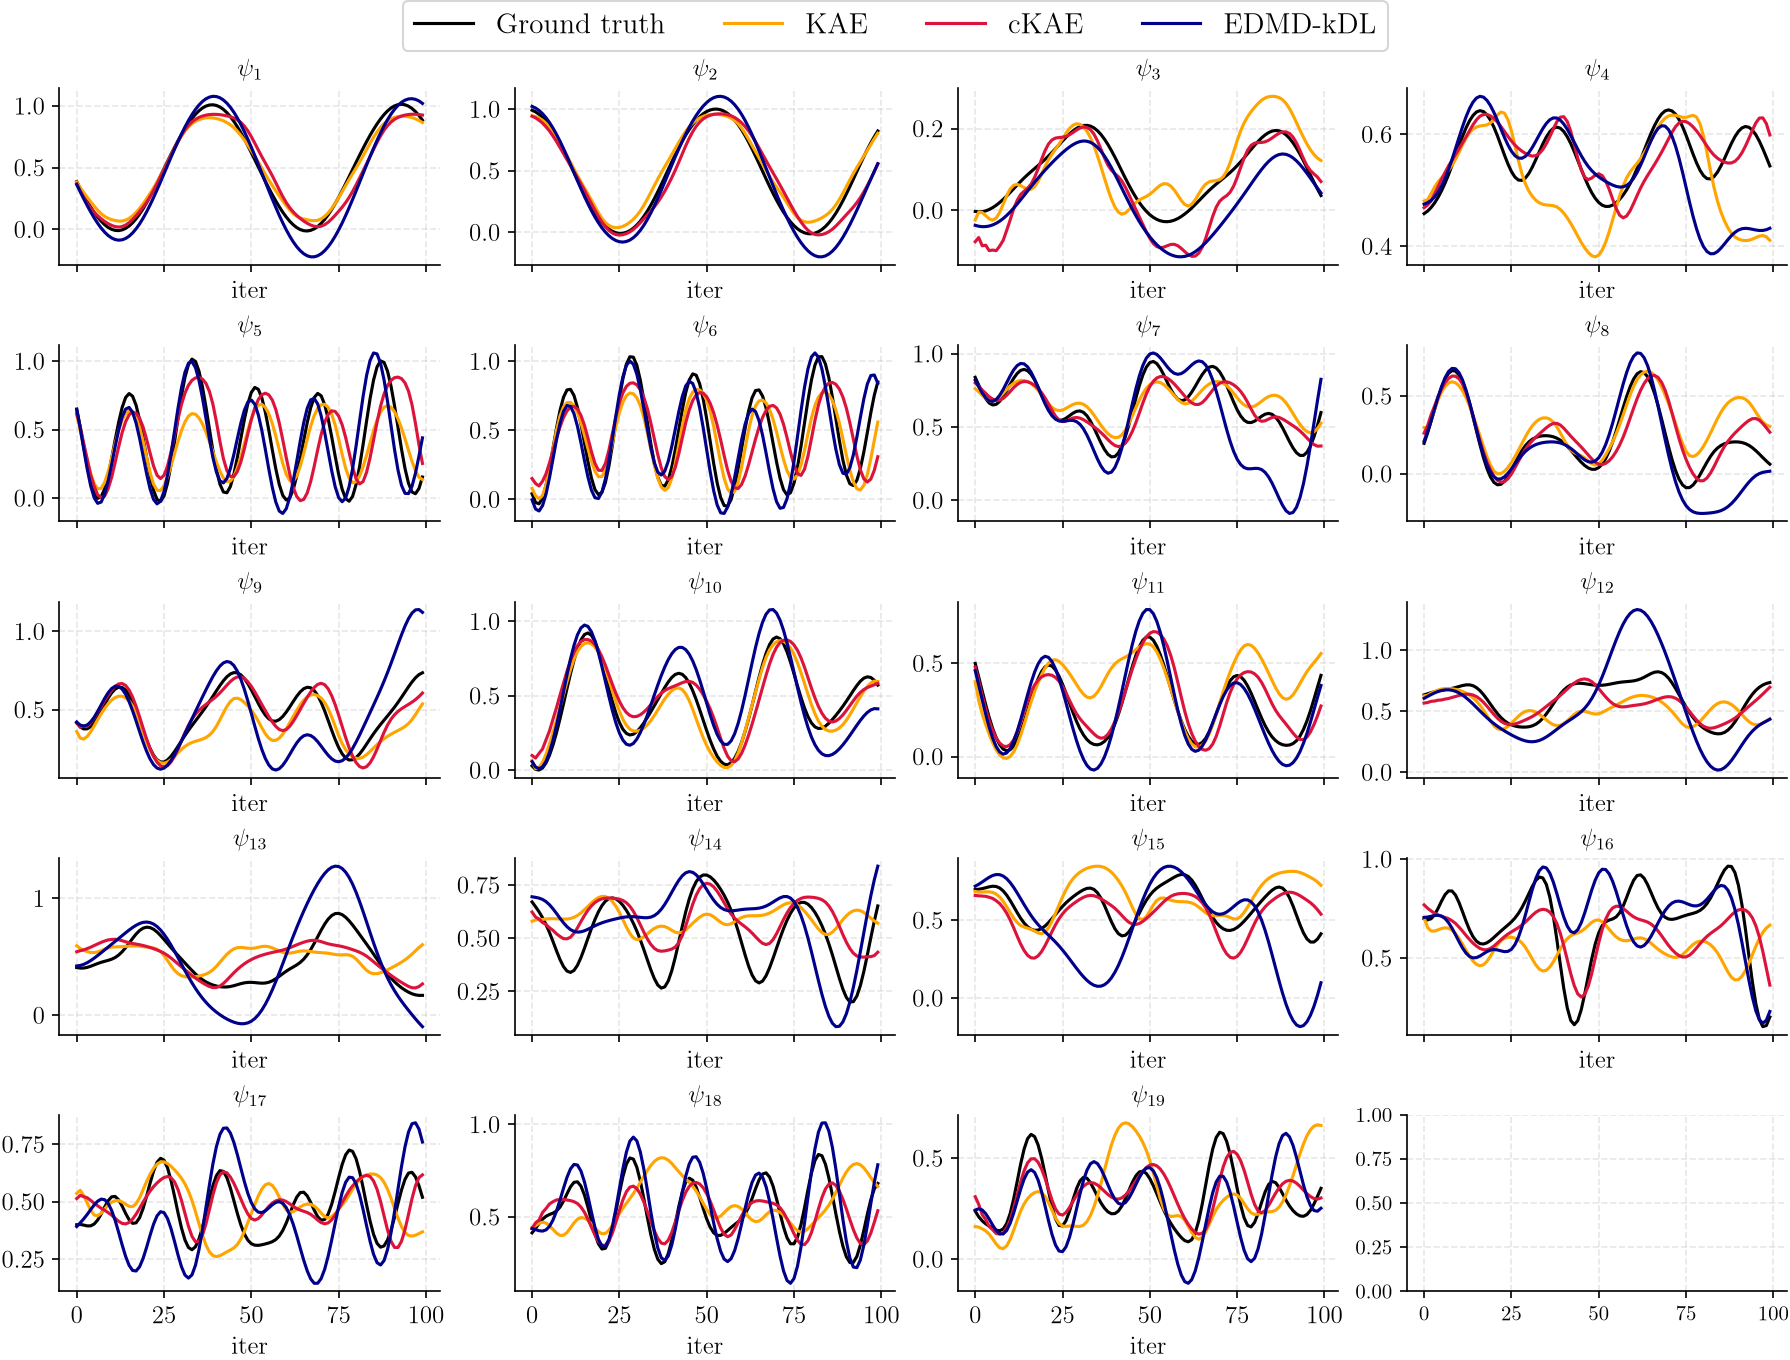

In [323]:
ncols = 4
nrows = int(np.ceil(dim/ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*3, nrows*1.75), sharex=True, constrained_layout=True)
ax = ax.flatten()
for i in range(dim):
    ax[i].plot(X_test_scaled[i, :], color='black',  label="Ground truth")
    #ax[i].plot(X_edmdrff_s[i, :], color='magenta',  label="EDMD-RFF")
    ax[i].plot(X_kae_s[i, :], color='orange',  label="KAE")
    ax[i].plot(X_ckae_s[i, :], color='crimson',  label="cKAE")
    ax[i].plot(X_edmd_s[i, :], color='darkblue',  label="EDMD-kDL")
    ax[i].set_xlabel('iter', fontsize=12)
    ax[i].set_title(rf'$\psi_{{{i+1}}}$', fontsize=12)
    ax[i].tick_params(axis='both', labelsize=12)

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(labels), fontsize=14, bbox_to_anchor=(0.5,1.05))
plt.show()

**error plot**

In [324]:
fig = plt.figure(figsize=(3.5,1.5))
t_test = np.arange(int(p_train*T), T)
plt.plot(t_test, np.linalg.norm(X_test_scaled - X_kae_s, axis=0) / np.linalg.norm(X_test_scaled, axis=0), lw=1., color='orange', label='KAE')
plt.plot(t_test, np.linalg.norm(X_test_scaled - X_ckae_s, axis=0) / np.linalg.norm(X_test_scaled, axis=0), lw=1., color='darkred', label='cKAE')
plt.plot(t_test, np.linalg.norm(X_test_scaled - X_edmd_s, axis=0) / np.linalg.norm(X_test_scaled, axis=0) , lw=1., color='darkblue', label='EDMD-kDL')
plt.xlabel('Time step', fontsize=12)
plt.ylabel('Prediction error', fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc = "upper left", ncols=3, bbox_to_anchor=(0., 1.2), fontsize=12, columnspacing=0.8, handlelength=1., handletextpad=0.2, frameon=False)
plt.grid(visible=False)

fig.savefig('figures/karman_vortex_prediction_error_latent.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)

### Full-space

In [279]:
X_edmd_r = A + X_edmd_s * B 
X_edmdrff_r = A + X_edmdrff_s * B
X_kae_r = A + X_kae_s * B
X_ckae_r = A + X_ckae_s * B

In [295]:
X_edmd = U[:,:r] @ X_edmd_r 
X_edmdrff = U[:,:r] @ X_edmdrff_r 
X_kae = U[:,:r] @ X_kae_r
X_ckae = U[:,:r] @ X_ckae_r 
X_test_recon_ = U[:,:r] @ X_test 

In [296]:

# reshape
X_test_orig = vorticity_data[...,int(p_train*T):].transpose(2,0,1) 
X_test_recon_ = (X_test_recon_.reshape(H, W, -1) + mean_flow).transpose(2,0,1)
X_edmdkdl = (X_edmd.reshape(H, W, -1) + mean_flow).transpose(2,0,1)
X_edmdrff = (X_edmdrff.reshape(H, W, -1) + mean_flow).transpose(2,0,1)
X_kae = (X_kae.reshape(H, W, -1) + mean_flow).transpose(2,0,1)
X_ckae = (X_ckae.reshape(H, W, -1) + mean_flow).transpose(2,0,1)

### snapshots

In [297]:
times = [0, 25, 50, 75, 99]
datasets = [X_test_orig, X_test_recon_, X_edmdrff, X_kae, X_ckae, X_edmdkdl]
row_labels = ['Original data', 'Ground truth', 'EDMD-RFF', 'KAE', 'cKAE', 'EDMD-kDL']
col_labels = ['(a) ', '(b) ', '(c) ', '(d) ', '(e) ']

fig, axes = plt.subplots(len(datasets), len(times), figsize=(2.25*len(times), 1.2*len(datasets)),
                          sharex=True, sharey=True, constrained_layout=True)

# Shared normalization across all panels (both rows)
norm = colors.CenteredNorm(halfrange=0.021, clip=True)

for row, data in enumerate(datasets):
    for col, t in enumerate(times):
        ax = axes[row, col]
        im = ax.imshow(data[t,...], cmap='seismic', norm=norm,
                        aspect='auto', interpolation='none')
        ax.set_xticks([])
        ax.set_yticks([])

        # Panel titles (only on top row)
        if row == 0:
            ax.set_title(col_labels[col] + rf'$t = {t+int(p_train*T)}$', fontsize=14)

    # Row labels (only on left-most column)
    axes[row, 0].text(-0.05, 0.5, row_labels[row], transform=axes[row, 0].transAxes,
                       rotation=90, va='center', ha='center', fontsize=14)

# One colorbar for the whole figure, matched to all axes
cbar = fig.colorbar(im, ax=axes, shrink=0.9, ticks=[-0.02, -0.01, 0.0, 0.01, 0.02])
cbar.ax.tick_params(labelsize=14)
fig.savefig('figures/karman_vortex_snapshots.pdf', bbox_inches='tight')
plt.close()

### prediction errors

In [298]:
fig = plt.figure(figsize=(3.5,1.5))
t_test = np.arange(int(p_train*T), T)
#plt.plot(t_test, np.linalg.matrix_norm(X_test - X_edmdrff) / np.linalg.matrix_norm(X_test) , lw=1., color='magenta', label='EDMD-RFF')
plt.plot(t_test, np.linalg.matrix_norm(X_test_orig - X_kae) / np.linalg.matrix_norm(X_test_orig), lw=1., color='orange', label='KAE')
plt.plot(t_test, np.linalg.matrix_norm(X_test_orig - X_ckae) / np.linalg.matrix_norm(X_test_orig), lw=1., color='darkred', label='cKAE')
plt.plot(t_test, np.linalg.matrix_norm(X_test_orig - X_edmdkdl) / np.linalg.matrix_norm(X_test_orig) , lw=1., color='darkblue', label='EDMD-kDL')
plt.xlabel('Time step', fontsize=12)
plt.ylabel('Prediction error', fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc = "upper left", ncols=3, bbox_to_anchor=(0., 1.2), fontsize=12, columnspacing=0.8, handlelength=1., handletextpad=0.2, frameon=False)
plt.grid(visible=False)

fig.savefig('figures/karman_vortex_prediction_error.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)

In [299]:
fig = plt.figure(figsize=(3.5,1.5))
t_test = np.arange(int(p_train*T), T)
#plt.plot(t_test, np.linalg.matrix_norm(X_test - X_edmdrff) / np.linalg.matrix_norm(X_test) , lw=1., color='magenta', label='EDMD-RFF')
plt.plot(t_test, np.linalg.matrix_norm(X_test_recon_ - X_kae) / np.linalg.matrix_norm(X_test_recon_), lw=1., color='orange', label='KAE')
plt.plot(t_test, np.linalg.matrix_norm(X_test_recon_ - X_ckae) / np.linalg.matrix_norm(X_test_recon_), lw=1., color='darkred', label='cKAE')
plt.plot(t_test, np.linalg.matrix_norm(X_test_recon_ - X_edmdkdl) / np.linalg.matrix_norm(X_test_recon_) , lw=1., color='darkblue', label='EDMD-kDL')
plt.xlabel('Time step', fontsize=12)
plt.ylabel('Prediction error', fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc = "upper left", ncols=3, bbox_to_anchor=(0., 1.2), fontsize=12, columnspacing=0.8, handlelength=1., handletextpad=0.2, frameon=False)
plt.grid(visible=False)

fig.savefig('figures/karman_vortex_prediction_error_pod.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)